# 2025년 냉장 상품 TOP 15 · 월별 입고량 비교

해당 연도에 제공된 전체 기간의 **입고 수량 합계 상위 15개 SKU**를 선정하고,
같은 상품들의 월별 입고량과 전월 대비 차이를 비교합니다. 월마다 TOP 15를 다시 뽑지 않습니다.

- 냉장: `storageMethod == "REFRIGERATION"` (원본의 `storageTemperature`와 일치 여부 점검).
- 수량: 양수인 `receivingQuantity` 합계. 부분 입고도 받은 수량만 포함합니다.
  주문 전체 상태가 `COLLECTED`인 행도 입고 수량이 있으면 포함합니다.
- 날짜: `shippingScheduledDate` **예정일 기준**. 실제 입고 완료 날짜는 원본에 없습니다.
- SKU 단위로 묶고 동률은 SKU 코드 오름차순. 상품명은 기간 내 마지막 표기를 사용합니다.
- 같은 ID라도 유통기한·제조일 등에 따라 분할된 행은 모두 합산합니다.
- 수량은 원본 상품 단위이며 kg·낱개로 환산하지 않습니다. 포장 규격이 다른 상품 간 비교에 유의하세요.

커널 **Python (hit-stocks-analysis)**에서 전체 셀을 실행하세요.
표·그래프는 `reports/inbound_refrigerated_2025/`에 저장됩니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib import font_manager

from hit_stocks_analysis import find_project_root

ROOT = find_project_root()
YEAR = 2025
TOP_N = 15
REPORT = ROOT / f"reports/inbound_refrigerated_{YEAR}"
REPORT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 80)
fonts = {font.name for font in font_manager.fontManager.ttflist}
for font in ("AppleGothic", "Malgun Gothic", "NanumGothic"):
    if font in fonts:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False

## 1. 원본 로딩과 월별 자료 범위

미관측 월은 0 대신 결측값으로 유지합니다. 날짜 관측 여부는 냉장 필터 적용 전 전체 원본으로
확인합니다. 원본에 날짜가 있다는 사실만으로 그날의 입고가 모두 완료되었다고 보장할 수는 없습니다.

In [2]:
files = sorted(ROOT.glob(f"inbound_{YEAR}-*.csv"))
assert files, f"{YEAR}년 inbound CSV가 없습니다."
columns = ["shippingScheduledDate", "id", "skuCode", "skuName", "storageMethod",
           "storageTemperature", "receivingQuantity"]
raw = pd.concat([
    pd.read_csv(path, usecols=columns, dtype="string", encoding="utf-8-sig")
    for path in files
], ignore_index=True)
raw["scheduled_date"] = pd.to_datetime(raw.shippingScheduledDate, errors="raise")
raw["quantity"] = pd.to_numeric(raw.receivingQuantity, errors="raise")
assert raw[columns].notna().all().all(), "필수 열 결측값을 확인하세요."
assert raw.scheduled_date.dt.year.eq(YEAR).all()
assert raw.quantity.ge(0).all(), "음수 수량의 업무상 의미를 확인하세요."
assert raw.storageMethod.eq(raw.storageTemperature).all(), "냉장 분류 불일치 확인 필요"
raw["month"] = raw.scheduled_date.dt.month
months = pd.Index(range(1, 13), name="month")
coverage = pd.DataFrame(index=months)
coverage["calendar_days"] = [pd.Timestamp(YEAR, month, 1).days_in_month for month in months]
coverage["observed_days"] = (
    raw.groupby("month").scheduled_date.nunique().reindex(months, fill_value=0)
)
coverage["first_date"] = raw.groupby("month").scheduled_date.min().reindex(months)
coverage["last_date"] = raw.groupby("month").scheduled_date.max().reindex(months)
coverage["status"] = np.select(
    [coverage.observed_days.eq(0), coverage.observed_days.eq(coverage.calendar_days)],
    ["자료 없음", "전체 날짜 관측"], default="부분 집계",
)
print("원본:", *[path.name for path in files], sep="\n")
print(f"원본 {len(raw):,}행 / 동일 ID 추가 행 {raw.id.duplicated().sum():,}개 (분할 행 유지)")
display(coverage)

원본:
inbound_2025-01-01_2025-03-31_2026-10-11_1511.csv
inbound_2025-04-01_2025-08-31_2026-10-11_1512.csv
inbound_2025-09-01_2025-12-31_2026-10-11_1521.csv
원본 505,244행 / 동일 ID 추가 행 344개 (분할 행 유지)


,calendar_days,observed_days,first_date,last_date,status
month,,,,,
1,31,31,2025-01-01,2025-01-31,전체 날짜 관측
2,28,28,2025-02-01,2025-02-28,전체 날짜 관측
3,31,31,2025-03-01,2025-03-31,전체 날짜 관측
4,30,30,2025-04-01,2025-04-30,전체 날짜 관측
5,31,31,2025-05-01,2025-05-31,전체 날짜 관측
6,30,30,2025-06-01,2025-06-30,전체 날짜 관측
7,31,31,2025-07-01,2025-07-31,전체 날짜 관측
8,31,31,2025-08-01,2025-08-31,전체 날짜 관측
9,30,30,2025-09-01,2025-09-30,전체 날짜 관측


## 2. 기간 전체 TOP 15와 월별 수량

TOP 15는 이 연도의 제공된 기간 전체 합계 기준입니다. 2026년은 연간 확정 순위가 아닙니다.
자료가 있는 월에서 해당 SKU의 입고 행이 없으면 0, 월 전체 자료가 없으면 결측입니다.

In [3]:
cold = raw.loc[raw.storageMethod.eq("REFRIGERATION") & raw.quantity.gt(0)].copy()
assert not cold.empty, "양의 입고 수량이 있는 냉장 상품이 없습니다."
names = (cold.sort_values("scheduled_date", kind="stable")
         .drop_duplicates("skuCode", keep="last").set_index("skuCode").skuName)
ranking = (cold.groupby("skuCode").quantity.sum().rename("total_quantity").reset_index()
           .sort_values(["total_quantity", "skuCode"], ascending=[False, True]))
top = ranking.head(TOP_N).set_index("skuCode").copy()
top.insert(0, "rank", range(1, len(top) + 1))
top.insert(1, "skuName", names.reindex(top.index))
top["share_of_refrigerated_pct"] = top.total_quantity / cold.quantity.sum() * 100
monthly = (cold.groupby(["skuCode", "month"]).quantity.sum().unstack()
           .reindex(index=top.index, columns=months).fillna(0).astype(float))
monthly.loc[:, coverage.observed_days.eq(0)] = np.nan
# 부분 집계 월도 수량은 보존하되, 전월 비교는 두 달 모두 전체 날짜가 관측된 경우만 표시합니다.
complete = coverage.observed_days.eq(coverage.calendar_days)
comparable = complete & complete.shift(1, fill_value=False)
change = monthly.diff(axis=1)
change.loc[:, ~comparable] = np.nan
previous = monthly.shift(1, axis=1)
change_pct = change.div(previous.where(previous.ne(0))).mul(100)
daily = monthly.div(coverage.observed_days.replace(0, np.nan), axis=1)
display(top.rename(columns={"rank": "순위", "skuName": "상품명",
    "total_quantity": "입고 수량", "share_of_refrigerated_pct": "냉장 전체 수량 비중(%)"}))
display(top[["skuName"]].join(monthly.rename(columns=lambda month: f"{month}월")))

,순위,상품명,입고 수량,냉장 전체 수량 비중(%)
skuCode,,,,
A21001710,1,비요뜨 쵸코링 138g,34542,2.923443
A21001791,2,서울우유 1000ml,16101,1.362699
A20002170,3,국내산 애호박 1개(18cm 이상),16068,1.359906
A20000255,4,맑은물에 촌두부 부침용 300g,15384,1.302016
A21017614,5,[배민이지] 갓 짜낸 1급A 우유 900ml,13978,1.18302
A20000183,6,청보 깐마늘 100g,13527,1.14485
A20000594,7,[배민이지] 무항생제 대란 10구,13074,1.106511
A21003598,8,풀무원 SOGA 부드러운찌개두부 300g,11982,1.01409
A20003366,9,국내산 햇감자 500g(3~5입),11079,0.937665


,skuName,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
skuCode,,,,,,,,,,,,,
A21001710,비요뜨 쵸코링 138g,3036.0,2448.0,2616.0,3240.0,3840.0,3360.0,3300.0,3474.0,2904.0,2556.0,1836.0,1932.0
A21001791,서울우유 1000ml,1632.0,1712.0,1456.0,1248.0,1280.0,1136.0,1264.0,1653.0,1264.0,912.0,1024.0,1520.0
A20002170,국내산 애호박 1개(18cm 이상),1347.0,1242.0,1128.0,1244.0,1845.0,1462.0,1329.0,1301.0,1077.0,1291.0,1440.0,1362.0
A20000255,맑은물에 촌두부 부침용 300g,1056.0,1320.0,1224.0,1092.0,1536.0,1572.0,1560.0,2172.0,1812.0,1584.0,456.0,0.0
A21017614,[배민이지] 갓 짜낸 1급A 우유 900ml,244.0,512.0,534.0,572.0,682.0,462.0,844.0,1572.0,1688.0,1868.0,2512.0,2488.0
A20000183,청보 깐마늘 100g,769.0,1034.0,1266.0,1148.0,1189.0,933.0,1179.0,1227.0,1090.0,1085.0,1142.0,1465.0
A20000594,[배민이지] 무항생제 대란 10구,1380.0,1380.0,1140.0,810.0,704.0,682.0,870.0,1186.0,1348.0,1238.0,1160.0,1176.0
A21003598,풀무원 SOGA 부드러운찌개두부 300g,1260.0,1320.0,1020.0,864.0,1284.0,1056.0,1164.0,1224.0,1044.0,924.0,396.0,426.0
A20003366,국내산 햇감자 500g(3~5입),711.0,750.0,731.0,810.0,1035.0,994.0,971.0,931.0,986.0,982.0,1013.0,1165.0


## 3. 월별 입고량과 전월 대비 증감

위 히트맵은 월별 수량, 아래 히트맵은 **이번 달 − 지난달** 수량입니다.
파랑은 감소, 빨강은 증가입니다. 회색 칸은 자료 없음 또는 비교 불가입니다.
첫 달과 부분 집계 월의 증감은 표시하지 않습니다. `*`가 있는 월은 부분 집계입니다.
2026년 10월은 11일까지의 수량이므로 9월 전체 수량과 직접 비교하지 않습니다.

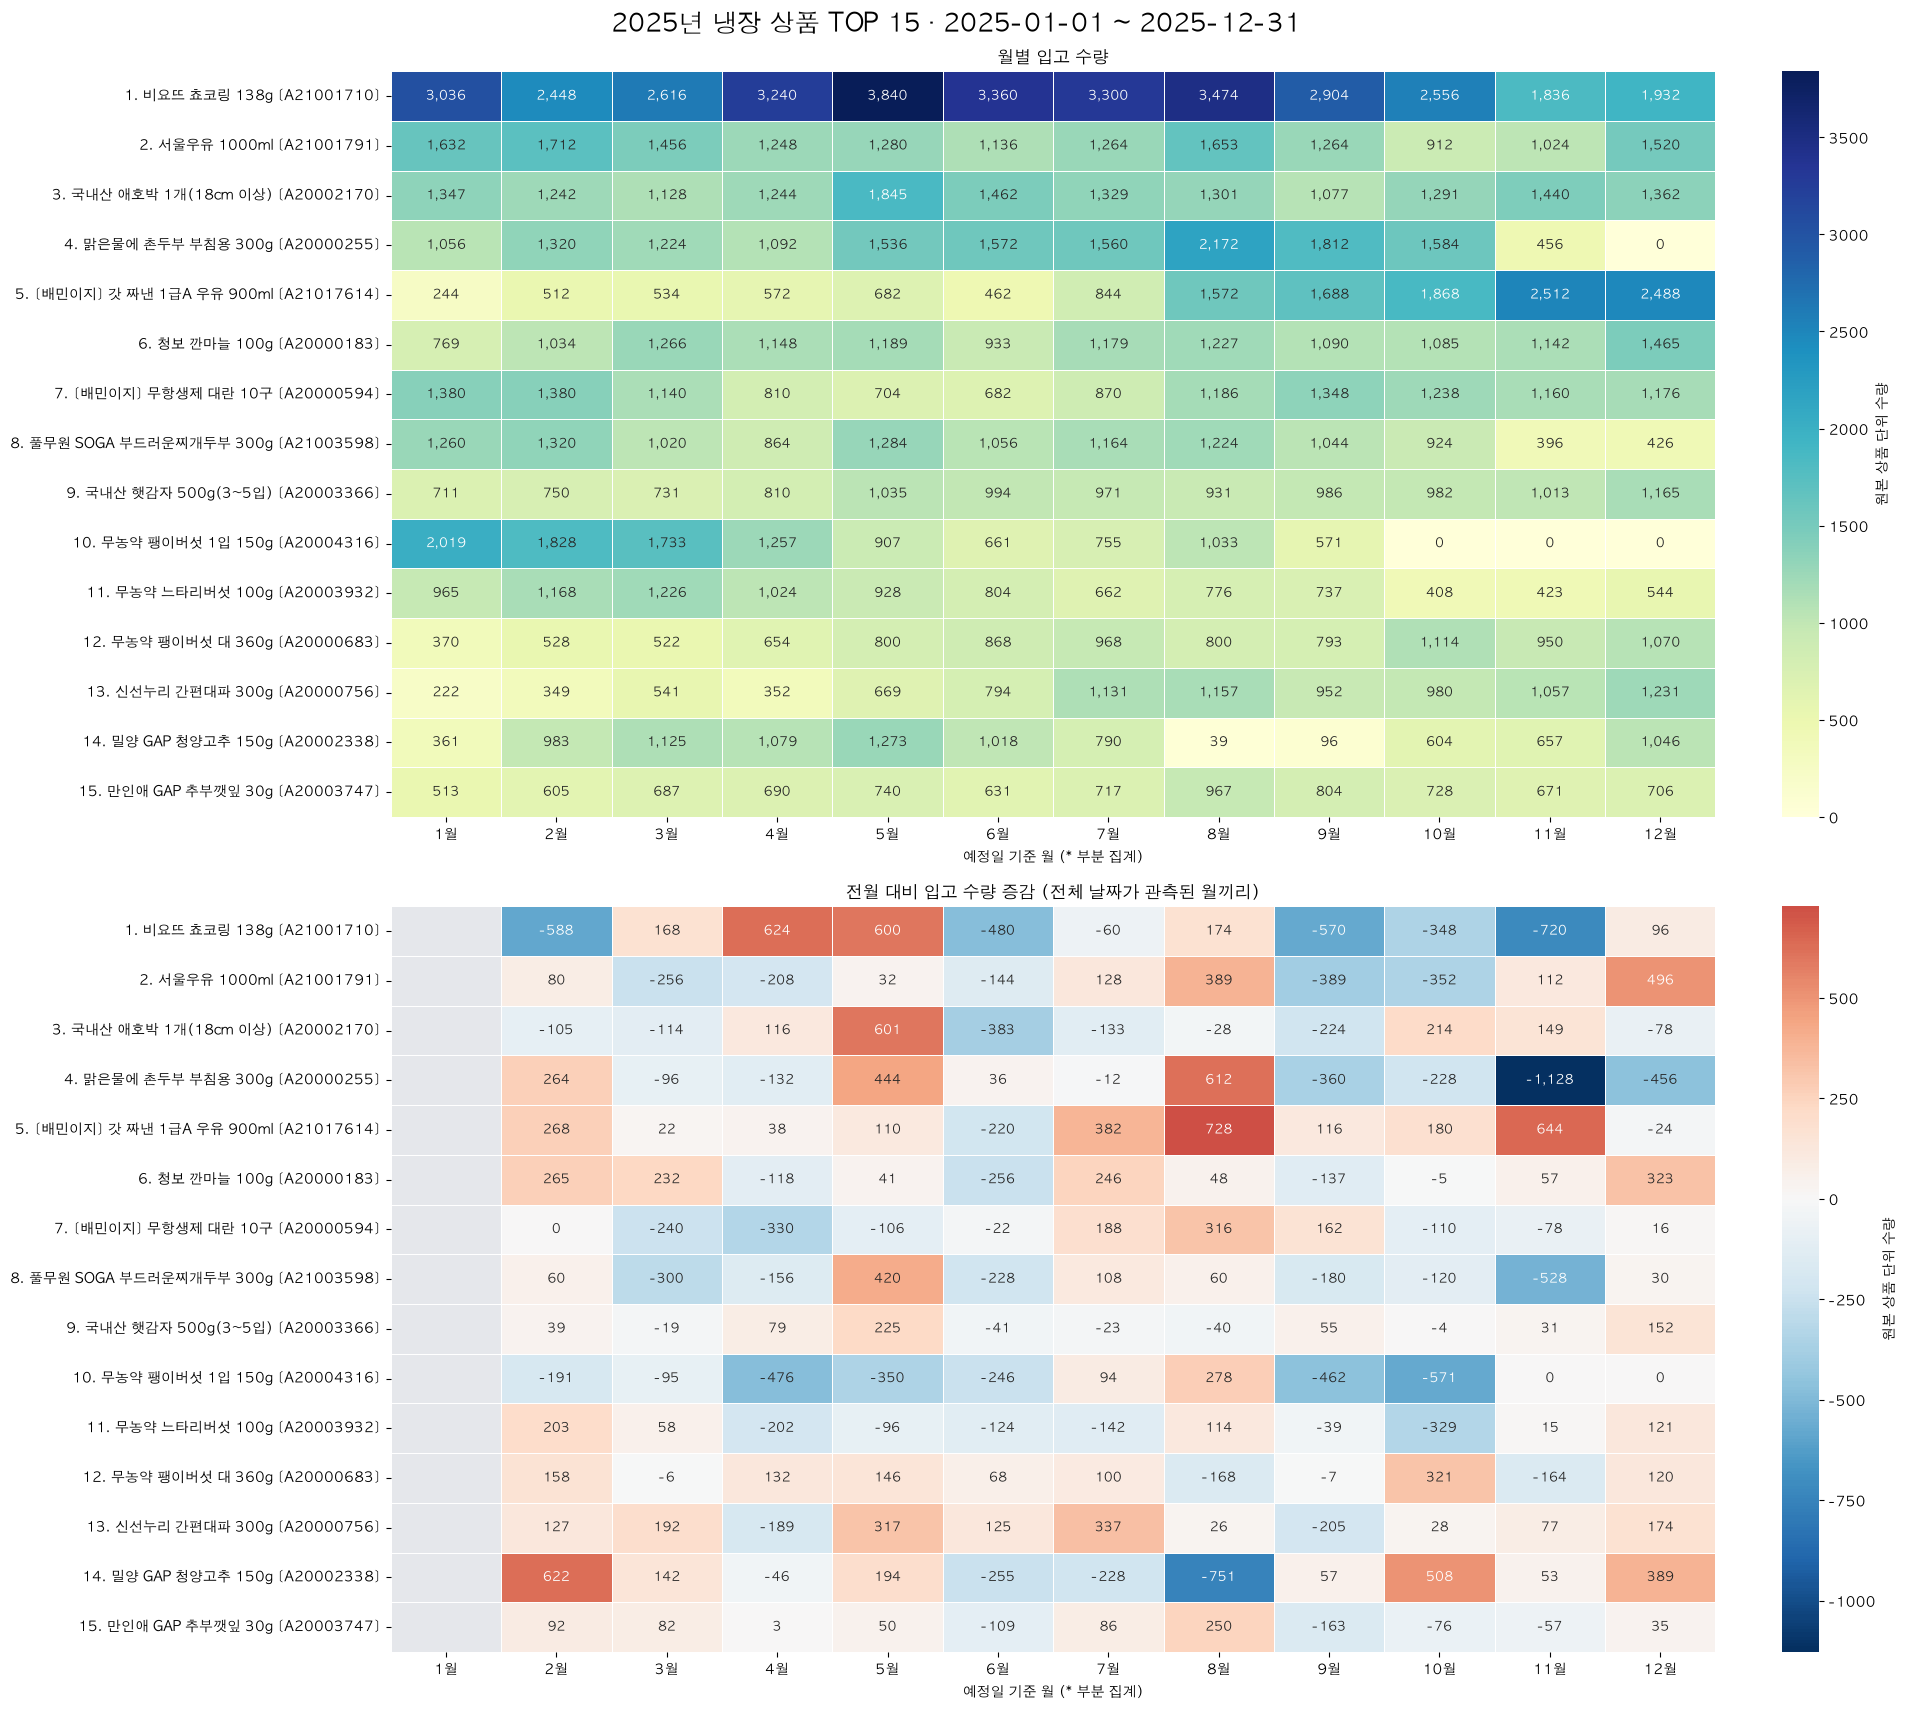

In [4]:
month_labels = [f"{month}월" + ("*" if coverage.loc[month, "status"] == "부분 집계" else "")
                for month in months]
product_labels = [f"{row['rank']}. {row.skuName} [{sku}]" for sku, row in top.iterrows()]
period = f"{raw.scheduled_date.min():%Y-%m-%d} ~ {raw.scheduled_date.max():%Y-%m-%d}"
fig, axes = plt.subplots(2, 1, figsize=(19, 17), layout="constrained")
for ax, table, title, cmap in [
    (axes[0], monthly, "월별 입고 수량", "YlGnBu"),
    (axes[1], change, "전월 대비 입고 수량 증감 (전체 날짜가 관측된 월끼리)", "RdBu_r"),
]:
    ax.set_facecolor("#e5e7eb")
    sns.heatmap(table, ax=ax, annot=True, fmt=",.0f", cmap=cmap,
                center=0 if table is change else None,
                linewidths=0.5, xticklabels=month_labels, yticklabels=product_labels,
                cbar_kws={"label": "원본 상품 단위 수량"}, annot_kws={"fontsize": 9})
    ax.set(title=title, xlabel="예정일 기준 월 (* 부분 집계)", ylabel="")
    ax.tick_params(axis="y", rotation=0)
    ax.tick_params(axis="x", rotation=0)
fig.suptitle(f"{YEAR}년 냉장 상품 TOP {len(top)} · {period}", fontsize=18)
fig.savefig(REPORT / "monthly_quantity_and_change.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. 관측일당 평균 입고량 추이

월별 수량을 **그달 원본에서 관측된 날짜 수**로 나눕니다. 상품별 입고가 발생한 날짜 수가 아닙니다.
월 길이 차이를 보정하며, 빈 주황색 점은 부분 집계 월입니다. 부분 월의 요일·연휴 구성은 다를 수
있어 완전한 월과 동일한 조건의 비교는 아닙니다. 상품마다 세로축 범위가 다릅니다.

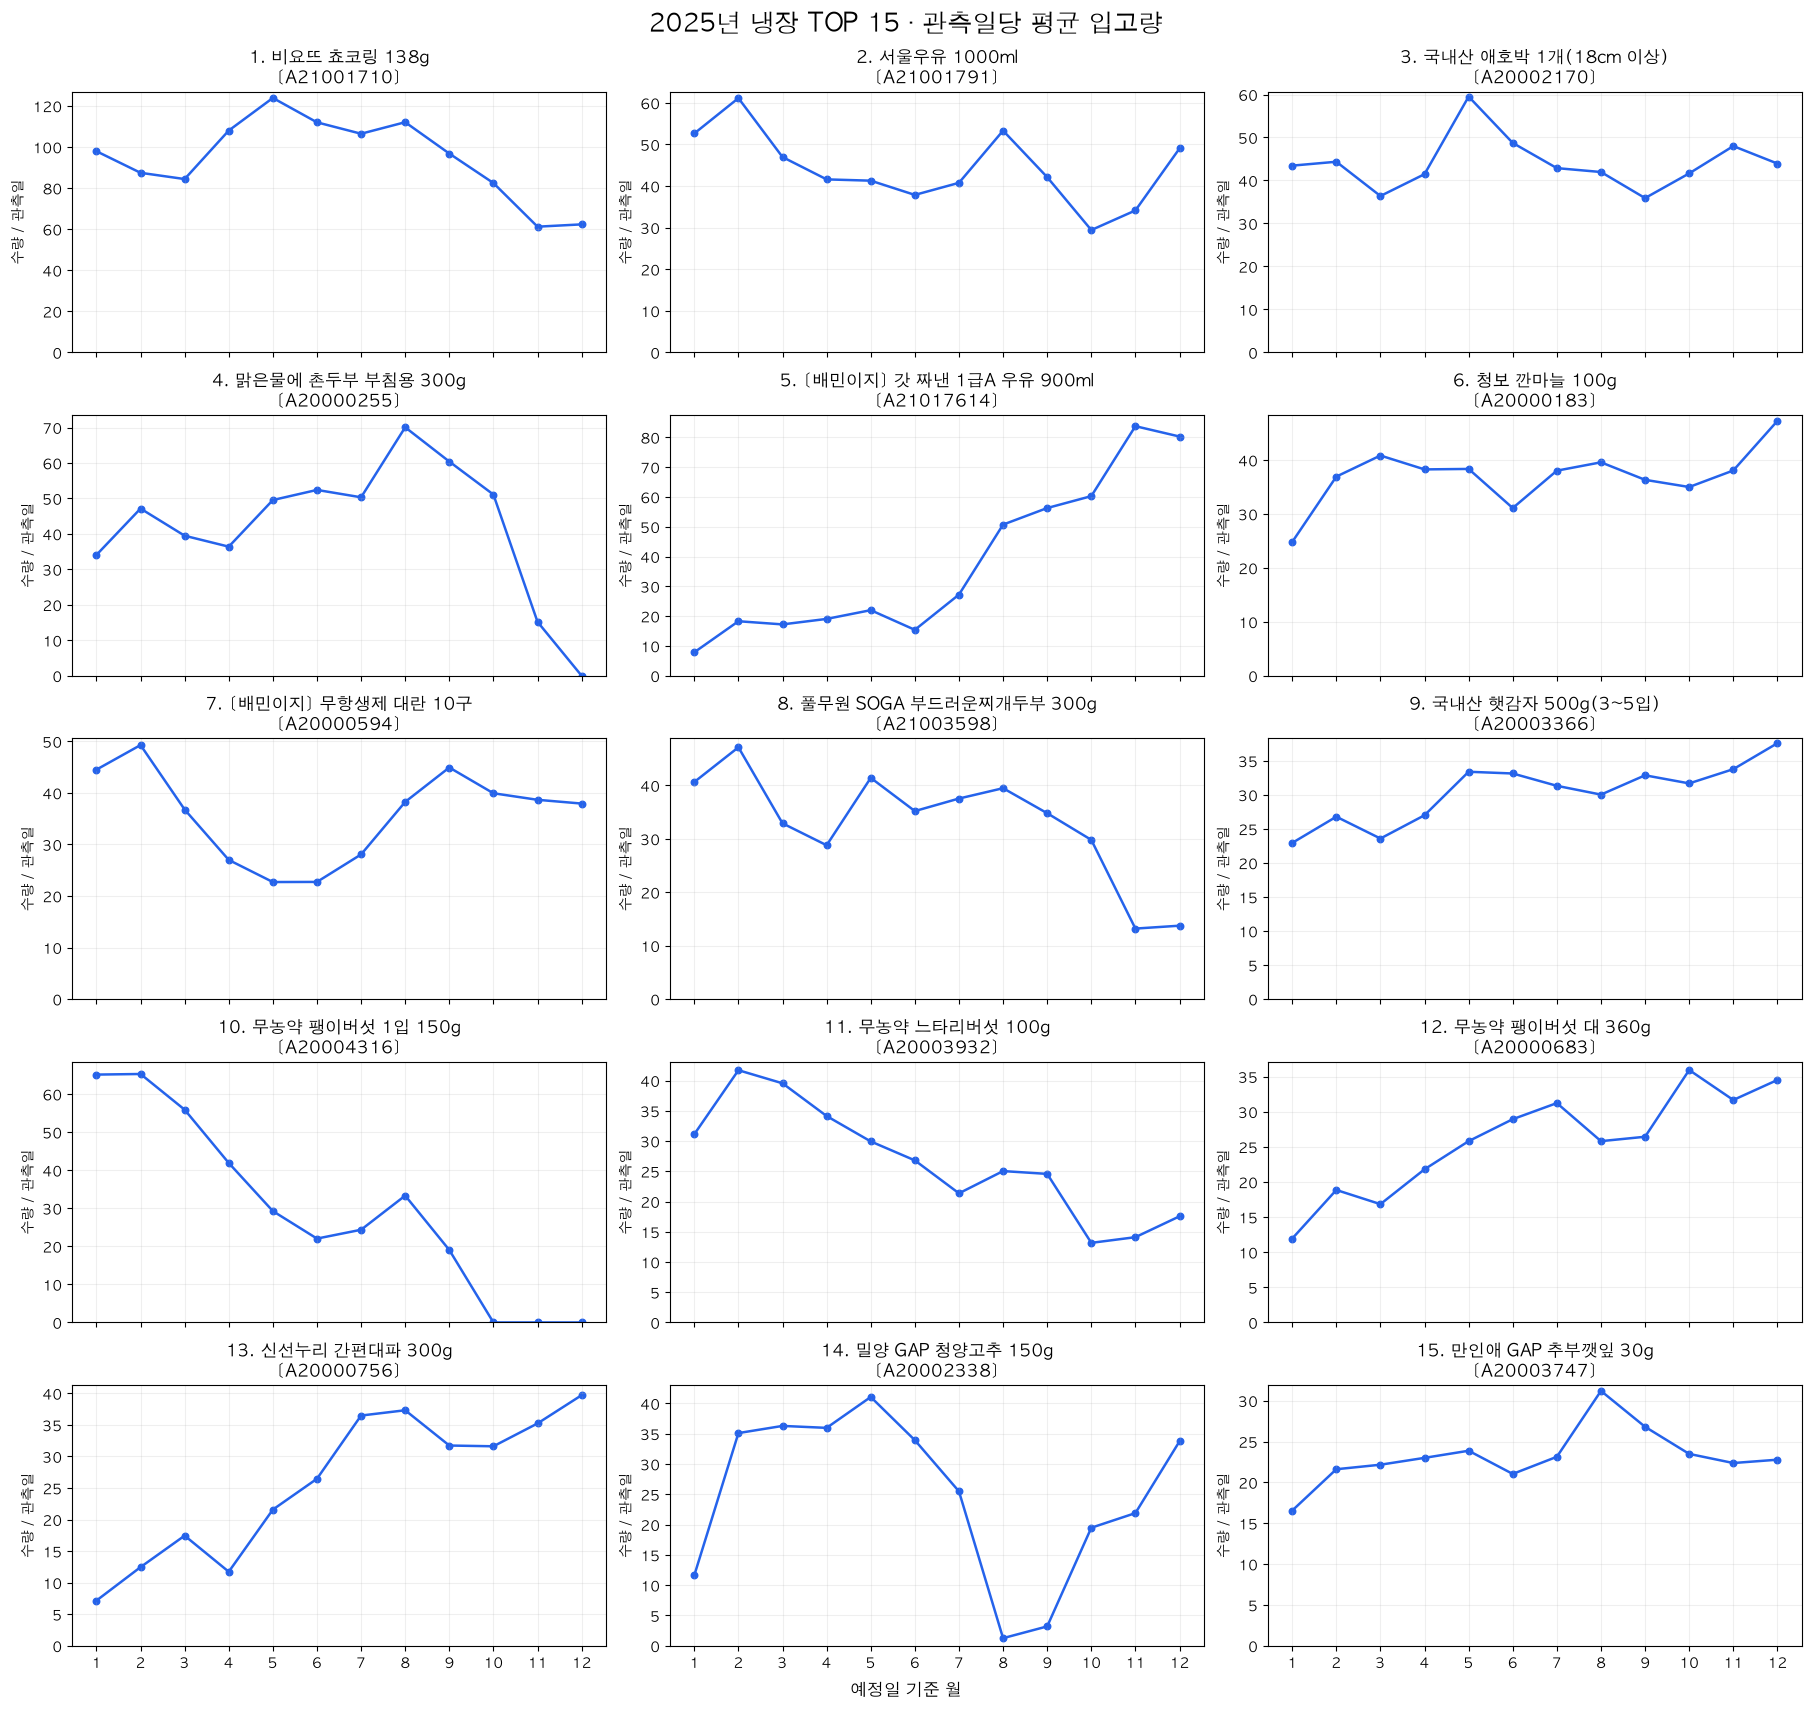

In [5]:
fig, axes = plt.subplots(5, 3, figsize=(18, 17), sharex=True, layout="constrained")
partial = coverage.status.eq("부분 집계")
for ax, (sku, row) in zip(axes.flat, top.iterrows()):
    values = daily.loc[sku]
    ax.plot(months, values, color="#2563eb", linewidth=1.8)
    ax.scatter(months[complete], values.loc[complete], color="#2563eb", s=22)
    ax.scatter(months[partial], values.loc[partial], facecolors="white",
               edgecolors="#ea580c", s=65, zorder=3, label="부분 집계")
    ax.set(title=f"{row['rank']}. {row.skuName}\n[{sku}]", ylabel="수량 / 관측일")
    ax.set_ylim(bottom=0)
    ax.set_xticks(months, labels=[str(month) for month in months])
    ax.grid(alpha=0.2)
    if partial.any():
        ax.legend(fontsize=8)
for ax in axes.flat[len(top):]:
    ax.set_visible(False)
fig.supxlabel("예정일 기준 월")
fig.suptitle(f"{YEAR}년 냉장 TOP {len(top)} · 관측일당 평균 입고량", fontsize=18)
fig.savefig(REPORT / "monthly_daily_average.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. 증감률·검증·결과 저장

증감률 = (이번 달 − 지난달) / 지난달 × 100. 전월 수량이 0이면 정의하지 않습니다.
1월, 미관측 월, 부분 집계 월과의 비교는 빈칸입니다. CSV는 Excel에서 열 수 있는 UTF-8 BOM으로
저장합니다. 재실행하면 해당 연도 결과만 갱신됩니다.

In [6]:
assert np.allclose(monthly.sum(axis=1), top.total_quantity.astype(float))
assert np.isclose(ranking.total_quantity.sum(), cold.quantity.sum())
assert monthly.loc[:, coverage.observed_days.eq(0)].isna().all().all()
assert change.loc[:, ~comparable].isna().all().all()
assert top.index.is_unique
outputs = {
    "top15": top,
    "monthly_quantity": top[["skuName"]].join(monthly),
    "monthly_change": top[["skuName"]].join(change),
    "monthly_change_pct": top[["skuName"]].join(change_pct),
    "monthly_daily_average": top[["skuName"]].join(daily),
    "monthly_coverage": coverage,
}
for name, table in outputs.items():
    table.to_csv(REPORT / f"{name}.csv", encoding="utf-8-sig")
with pd.ExcelWriter(REPORT / f"inbound_refrigerated_{YEAR}.xlsx") as writer:
    for name, table in outputs.items():
        table.to_excel(writer, sheet_name=name)
display(change_pct.round(1).rename(columns=lambda month: f"{month}월 증감률(%)"))
print("수량 합계 및 미관측/부분 월 처리 검증 통과")
print("결과 저장:", REPORT)

month,1월 증감률(%),2월 증감률(%),3월 증감률(%),4월 증감률(%),5월 증감률(%),6월 증감률(%),7월 증감률(%),8월 증감률(%),9월 증감률(%),10월 증감률(%),11월 증감률(%),12월 증감률(%)
skuCode,,,,,,,,,,,,
A21001710,NaN,-19.4,6.9,23.9,18.5,-12.5,-1.8,5.3,-16.4,-12.0,-28.2,5.2
A21001791,NaN,4.9,-15.0,-14.3,2.6,-11.2,11.3,30.8,-23.5,-27.8,12.3,48.4
A20002170,NaN,-7.8,-9.2,10.3,48.3,-20.8,-9.1,-2.1,-17.2,19.9,11.5,-5.4
A20000255,NaN,25.0,-7.3,-10.8,40.7,2.3,-0.8,39.2,-16.6,-12.6,-71.2,-100.0
A21017614,NaN,109.8,4.3,7.1,19.2,-32.3,82.7,86.3,7.4,10.7,34.5,-1.0
A20000183,NaN,34.5,22.4,-9.3,3.6,-21.5,26.4,4.1,-11.2,-0.5,5.3,28.3
A20000594,NaN,0.0,-17.4,-28.9,-13.1,-3.1,27.6,36.3,13.7,-8.2,-6.3,1.4
A21003598,NaN,4.8,-22.7,-15.3,48.6,-17.8,10.2,5.2,-14.7,-11.5,-57.1,7.6
A20003366,NaN,5.5,-2.5,10.8,27.8,-4.0,-2.3,-4.1,5.9,-0.4,3.2,15.0


수량 합계 및 미관측/부분 월 처리 검증 통과
결과 저장: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/inbound_refrigerated_2025
